# `tl.interaction_changed_genes`: vectorization-equivalence check vs a per-gene `scipy.stats` loop

**Scope, stated honestly:** this notebook is a *vectorization-equivalence check*, not an external validation. The "reference" below re-types astrolabe's own algorithm — the same contacted/non-contacted split, the same zero-variance guard, the same test choice — as a plain per-gene `scipy.stats.mannwhitneyu` loop. What it validates is that astrolabe's all-genes-at-once vectorized Mann-Whitney implementation (ranking, tie correction, continuity correction, normal approximation) reproduces scipy's per-gene arithmetic exactly; it cannot detect a flaw in the *method design*, because both sides share it by construction. The real external reference for this analysis is Giotto's `findInteractionChangedGenes` (Dries et al. 2021, Genome Biology) — an R package, out of scope for this Python benchmark suite.

For every (receiver cell type, neighbor cell type) pair, `interaction_changed_genes` tests whether "contacted" cells (>=1 spatial neighbor of the given type) differ in expression from non-contacted cells of the same type. Since the overhaul, astrolabe's default **`pval` is a label-permutation p-value** (cells in tissue are not exchangeable, so the asymptotic p is anti-conservative under spatial autocorrelation — the permutation null is also what Giotto uses); the asymptotic Mann-Whitney p is still reported as **`p_asymptotic`**, and that is the scipy-comparable column this notebook checks. The permutation path itself has no independent Python implementation to compare against and is exercised by unit tests, not validated here.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import pandas as pd
import astrolabe as ab
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## Dataset

`ab.datasets.xenium_tiny()` with Leiden clusters as cell types and a spatial
graph to define "contact."

In [2]:
mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.pp.highly_variable_genes(mdata)
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=0.5)
ab.tl.spatial_neighbors(mdata)

adata = mdata["xenium"]
adata

INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\scipy_stats\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:881: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\scipy_stats\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 20999 transcript detections


INFO:astrolabe.pipeline:filter_xenium: 358 cells × 520 genes


...

INFO:astrolabe.pipeline:filter_xenium: done — 333 cells × 255 genes


INFO:astrolabe.tl._graph:transcriptional_neighbors: 333 cells -> uns['neighbors']


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 3 clusters


INFO:astrolabe.tl._graph:spatial_neighbors: 333 cells, 2302 edges (mean degree 6.9) [generic]


AnnData object with n_obs × n_vars = 333 × 255
    obs: 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'total_counts_all_features', 'nucleus_to_cell_area_ratio', 'has_nucleus', 

## Astrolabe: `tl.interaction_changed_genes`

Run with the default permutation null (`n_perms=200`), so the returned frame carries both the default `pval` (permutation) and `p_asymptotic` (the vectorized Mann-Whitney normal approximation under comparison here).

In [3]:
_t0 = time.perf_counter()
icg_astro = ab.tl.interaction_changed_genes(
    mdata, groupby="leiden", method="wilcoxon", fdr_scope="pair",
)
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime (incl. 200-permutation null): {t_astro_s:.4f}s")
icg_astro.head()

INFO:astrolabe.tl._icg:ICG [0 | nb=1]: 52 vs 31 cells


INFO:astrolabe.tl._icg:ICG [0 | nb=2]: 67 vs 16 cells


INFO:astrolabe.tl._icg:ICG [1 | nb=0]: 74 vs 64 cells


INFO:astrolabe.tl._icg:ICG [1 | nb=2]: 62 vs 76 cells


INFO:astrolabe.tl._icg:ICG [2 | nb=0]: 97 vs 15 cells


INFO:astrolabe.tl._icg:ICG [2 | nb=1]: 45 vs 67 cells


INFO:astrolabe.tl._icg:interaction_changed_genes: permutation null (200 perms × 6 pairs)


INFO:astrolabe.tl._icg:interaction_changed_genes: 1530 rows across 6 tested pairs


astrolabe runtime (incl. 200-permutation null): 5.7154s


,cell_type,neighbor_type,gene,statistic,p_asymptotic,mean_contacted,mean_non_contacted,log2fc,n_contacted,n_non_contacted,pval,pval_adj
0,0,1,ACKR1,754.0,0.067995,0.000000,0.067758,-27.119160,52,31,1.0,1.0
1,0,1,ACTA2,763.5,0.645709,0.259846,0.296390,-0.164784,52,31,1.0,1.0
2,0,1,ACTG2,857.0,0.289674,0.056322,0.022733,1.378917,52,31,1.0,1.0
3,0,1,ADAM28,914.5,0.034904,0.076332,0.000000,26.715841,52,31,1.0,1.0
4,0,1,ADAMTS1,837.0,0.611571,0.108319,0.055889,1.248852,52,31,1.0,1.0


## Reference: the identical contacted/non-contacted split, tested with plain `scipy.stats`

Reproduces the same contact split astrolabe computes (any nonzero connectivity weight from a receiver cell to a neighbor-type cell counts as "contacted"; self pairs skipped, matching astrolabe's `skip_self_pairs=True` default), then runs `scipy.stats.mannwhitneyu` per gene with `method='asymptotic'` and continuity correction — again matching astrolabe's implementation by construction (that's what makes this an equivalence check, not a validation).

One edge case needs explicit handling: for a gene that's constant (e.g. all zero) across both groups combined, the Mann-Whitney normal approximation has zero variance and plain `scipy.stats.mannwhitneyu` returns `nan`. Astrolabe guards this case and reports `p=1.0` instead, so the reference loop applies the same guard to match.

In [4]:
categories = adata.obs["leiden"].cat.categories.tolist()
conn = adata.obsp["spatial_neighbors_connectivities"]
X = np.asarray(adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X, dtype=np.float64)
gene_names = list(adata.var_names)
codes = adata.obs["leiden"].cat.codes.to_numpy()
type_idx = {ct: np.where(codes == i)[0] for i, ct in enumerate(categories)}

_t0 = time.perf_counter()
rows = []
for ct_a in categories:
    idx_a = type_idx[ct_a]
    conn_a = conn[idx_a, :]
    for ct_b in categories:
        if ct_a == ct_b:
            continue  # matches astrolabe's skip_self_pairs=True default
        idx_b = type_idx[ct_b]
        if len(idx_b) == 0:
            continue
        neighbor_counts = np.asarray(conn_a[:, idx_b].sum(axis=1)).ravel()
        local_cont = np.where(neighbor_counts > 0)[0]
        local_non = np.where(neighbor_counts == 0)[0]
        if len(local_cont) < 10 or len(local_non) < 10:
            continue

        X_cont = X[idx_a[local_cont], :]
        X_non = X[idx_a[local_non], :]

        pvals = np.empty(len(gene_names))
        for g in range(len(gene_names)):
            col_cont, col_non = X_cont[:, g], X_non[:, g]
            if np.ptp(np.concatenate([col_cont, col_non])) == 0:
                # Zero-variance combined column: matches astrolabe's own
                # sigma > 0 guard rather than propagating scipy's nan.
                pvals[g] = 1.0
            else:
                _, p = mannwhitneyu(
                    col_cont, col_non,
                    method="asymptotic", use_continuity=True,
                )
                pvals[g] = p
        pvals_adj = multipletests(pvals, method="fdr_bh")[1]

        for g, gene in enumerate(gene_names):
            rows.append({
                "cell_type": ct_a, "neighbor_type": ct_b, "gene": gene,
                "pval_ref": pvals[g], "pval_adj_ref": pvals_adj[g],
            })

t_ref_s = time.perf_counter() - _t0
print(f"reference runtime: {t_ref_s:.4f}s")

icg_ref = pd.DataFrame(rows)
icg_ref.head()

reference runtime: 1.0467s


,cell_type,neighbor_type,gene,pval_ref,pval_adj_ref
0,0,1,ACKR1,0.067995,0.589698
1,0,1,ACTA2,0.645709,0.914755
2,0,1,ACTG2,0.289674,0.687652
3,0,1,ADAM28,0.034904,0.508993
4,0,1,ADAMTS1,0.611571,0.904684


## Agreement (on `p_asymptotic` — the scipy-comparable column)

`pval` and `pval_adj` are permutation-based since the overhaul and have no scipy counterpart, so the comparison targets `p_asymptotic`. The reference's BH-adjusted values are checked against a BH re-application to astrolabe's own `p_asymptotic` (statsmodels vs astrolabe's internal BH would otherwise be conflated with the p-value comparison).

Pearson r (-log10 p_asymptotic) = 1.000000
max |p_asymptotic - reference p| = 0.00e+00
max |BH(p_asymptotic) - reference BH| = 0.00e+00
Runtime: astrolabe 5.7154s (incl. permutation null) vs per-gene scipy loop 1.0467s (asymptotic only) — not apples-to-apples: astrolabe's call also ran a 200-permutation null the reference skips.


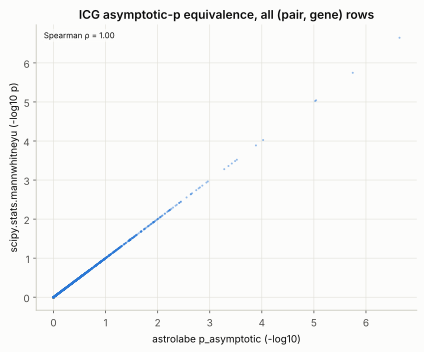

In [5]:
merged = icg_astro.merge(icg_ref, on=["cell_type", "neighbor_type", "gene"])
assert len(merged) == len(icg_astro), "pair sets should match exactly"

# pvals can be exactly 0 in floating point (deep in the tail of the normal
# approximation); clip before -log10 so the comparison isn't dominated by a
# handful of -inf/+inf outliers that both sides agree are "very significant."
eps = 1e-300
neglog_astro = -np.log10(np.clip(merged["p_asymptotic"], eps, 1.0))
neglog_ref = -np.log10(np.clip(merged["pval_ref"], eps, 1.0))

r = np.corrcoef(neglog_astro, neglog_ref)[0, 1]
max_diff = float((merged["p_asymptotic"] - merged["pval_ref"]).abs().max())

# BH re-applied per pair to astrolabe's asymptotic p, vs statsmodels' BH
bh_astro = merged.groupby(["cell_type", "neighbor_type"], observed=True)[
    "p_asymptotic"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
adj_max_diff = float((bh_astro - merged["pval_adj_ref"]).abs().max())

print(f"Pearson r (-log10 p_asymptotic) = {r:.6f}")
print(f"max |p_asymptotic - reference p| = {max_diff:.2e}")
print(f"max |BH(p_asymptotic) - reference BH| = {adj_max_diff:.2e}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s (incl. permutation null) vs "
      f"per-gene scipy loop {t_ref_s:.4f}s (asymptotic only) — not "
      f"apples-to-apples: astrolabe's call also ran a 200-permutation null "
      f"the reference skips.")

assert max_diff < 1e-10, "vectorized Mann-Whitney must reproduce scipy exactly"

panel = ab.pl.scatter(
    adata, x=neglog_astro.to_numpy(), y=neglog_ref.to_numpy(), annotate_corr=True,
    xlabel="astrolabe p_asymptotic (-log10)",
    ylabel="scipy.stats.mannwhitneyu (-log10 p)",
    title="ICG asymptotic-p equivalence, all (pair, gene) rows",
)
panel.show()

## Interpretation

Both sides run the identical asymptotic, tie-corrected, continuity-corrected Mann-Whitney U test on the identical contacted/non-contacted split, so `p_asymptotic` lands on `y = x` to floating-point precision — confirming the vectorized ranking/tie-correction arithmetic, which is all this notebook can confirm. It says nothing about whether the *method* (the contact split, or the choice of test) is sound, because the reference re-types that method rather than implementing it independently; and it does not touch astrolabe's default significance path (`pval`, the label-permutation null), which exists precisely because the asymptotic p compared here is anti-conservative under spatial autocorrelation. An external validation would compare against Giotto's `findInteractionChangedGenes` (R) on a shared dataset — out of scope for this Python-only benchmark suite.